# Quickstart

`spatialbatch` turns on-disk {class}`~spatialdata.SpatialData` stores into a sharded zarr collection and streams shuffled mini-batches of **cells** from it.
For every cell a batch can hold any of three element types, all aligned along axis 0:

- the **table**: the cell's expression (`X`), its `obs` annotations and its coordinates;
- **images**: a tile of each image element, centered on the cell;
- **labels**: a tile of each segmentation mask, centered on the cell.

This quickstart uses a *small synthetic* SpatialData to show the three steps every workflow shares: **convert → load → iterate**.
For real Xenium data, see the guides by element type:

- {doc}`scrnaseq`: the table only (expression + annotations);
- {doc}`images`: image and labels tiles only;
- {doc}`multimodal`: table and images together.

All three load **the same collection**: write it once, then mini-batch whichever elements a model needs.

## Configure zarrs

Pointing zarr at the {doc}`zarrs-python <zarrs:index>` codec pipeline is what makes local reads fast.
Do this once, before reading or writing any store (see {doc}`../zarr-configuration`).

In [1]:
import warnings

import zarr

zarr.config.set({"codec_pipeline.path": "zarrs.ZarrsCodecPipeline"})
for msg in (
    "Consolidated metadata is currently not part in the Zarr format 3 specification.*",
    "The index of the dataframe is not monotonic increasing.*",
):
    warnings.filterwarnings("ignore", message=msg)

## A small example SpatialData

Real workflows start from your own SpatialData stores, such as a Xenium output read with `spatialdata-io`.
Here we build one with the same layout: a `morphology_focus` image with a bright blob per cell, a `cell_labels` mask, the cells as `cell_circles`, and a `table` of sparse counts that annotates them.

In [2]:
import anndata as ad
import numpy as np
import pandas as pd
import scipy.sparse as sp
import spatialdata as sd
from spatialdata.models import Image2DModel, Labels2DModel, ShapesModel, TableModel

rng = np.random.default_rng(0)
height = width = 4096
n_cells, n_genes, radius = 2_000, 100, 8

centers = rng.uniform(radius, [width - radius, height - radius], (n_cells, 2))  # (x, y) in pixels
yy, xx = np.mgrid[-radius : radius + 1, -radius : radius + 1]
disk = (xx**2 + yy**2) <= radius**2
image = rng.integers(0, 200, (1, height, width), dtype=np.uint16)  # background noise
labels = np.zeros((height, width), dtype=np.uint32)
for i, (cx, cy) in enumerate(centers.round().astype(int)):
    window = (slice(cy - radius, cy + radius + 1), slice(cx - radius, cx + radius + 1))
    image[0][window][disk] = rng.integers(2_000, 4_000)
    labels[window][disk] = i + 1

cell_ids = [f"cell_{i}" for i in range(n_cells)]
circles = ShapesModel.parse(centers, geometry=0, radius=np.full(n_cells, float(radius)), index=cell_ids)
table = ad.AnnData(
    X=sp.random(n_cells, n_genes, density=0.1, format="csr", dtype=np.float32, random_state=0),
    obs=pd.DataFrame(
        {
            "region": pd.Categorical(["cell_circles"] * n_cells),
            "cell_id": cell_ids,
            "cell_type": pd.Categorical(rng.choice(["B", "T", "NK"], n_cells)),
        },
        index=cell_ids,
    ),
    var=pd.DataFrame(index=[f"gene_{i}" for i in range(n_genes)]),
)
sdata = sd.SpatialData(
    images={"morphology_focus": Image2DModel.parse(image, dims=("c", "y", "x"))},
    labels={"cell_labels": Labels2DModel.parse(labels, dims=("y", "x"))},
    shapes={"cell_circles": circles},
    tables={"table": TableModel.parse(table, region="cell_circles", region_key="region", instance_key="cell_id")},
)
sdata.write("example.zarr", overwrite=True)
sdata = sd.read_zarr("example.zarr")  # spatialbatch streams from disk, so the SpatialData must be backed
sdata

/Users/rushin.gindra/Documents/Research/SpatialProjects/spatialdatabase/spatialbatch/.claude/worktrees/add-tutorials/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


no parent found for <ome_zarr.reader.Label object at 0x154a27f50>: None


SpatialData object, with associated Zarr store: /Users/rushin.gindra/Documents/Research/SpatialProjects/spatialdatabase/spatialbatch/.claude/worktrees/add-tutorials/docs/tutorials/example.zarr
├── Images
│     └── 'morphology_focus': DataArray[cyx] (1, 4096, 4096)
├── Labels
│     └── 'cell_labels': DataArray[yx] (4096, 4096)
├── Shapes
│     └── 'cell_circles': GeoDataFrame shape: (2000, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (2000, 100)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), cell_circles (Shapes)

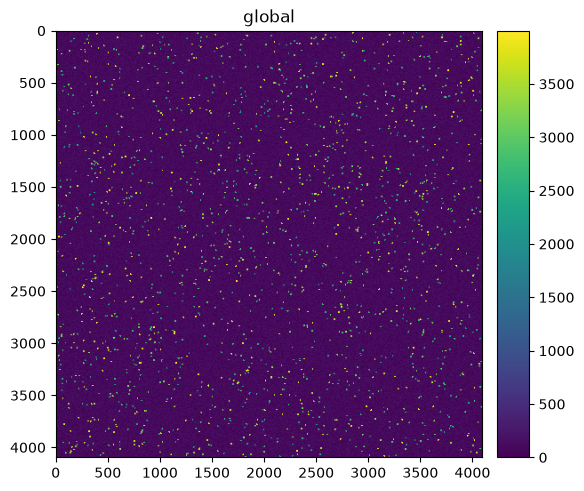

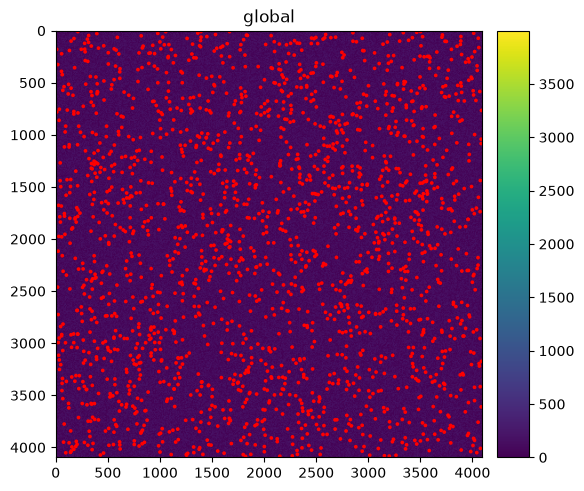

In [3]:
import spatialdata_plot  # noqa: F401  # registers the `.pl` plotting accessor

sdata.pl.render_images().pl.show()
sdata.pl.render_images("morphology_focus").pl.render_shapes(
    "cell_circles", fill_alpha=0, outline_alpha=1.0, outline_color="red"
).pl.show()

## Convert into a collection

{meth}`~spatialbatch.SpatialDatasetCollection.add_sdatas` writes each SpatialData as one dataset of a sharded zarr collection.
Write **every element you may want later**; each loader picks a subset.

**Shuffling, the spatialbatch way.** [annbatch](https://annbatch.readthedocs.io) shuffles rows across files when writing, so that contiguous reads are already random.
Pixels can't be moved around like that, so `spatialbatch` does the opposite on disk: it sorts each slide's cells along a **Morton (Z-order) curve**, so that a run of consecutive cells covers one compact region of the image.
A chunk of cells is then read as a few large windows instead of many small tiles.
Randomness comes when reading: the sampler draws chunks from random places in any slide and shuffles them in memory (see below).

By default a tile is **1024 × 1024 pixels**, and images and labels are stored in **128 × 128 pixel chunks**, so a tile side spans 8 chunks.
That's more context than most models take as input: crop it to the size your model needs when loading (see [Transforms](#transforms)).

In [4]:
from spatialbatch import SpatialDatasetCollection

collection = SpatialDatasetCollection(zarr.open_group("quickstart_collection.zarr", mode="w"))
collection.add_sdatas(["example.zarr"], images=["morphology_focus"], labels=["cell_labels"])

dataset = next(iter(collection))
image_array = dataset["images"]["morphology_focus"]
print("image chunks:", image_array.chunks, "shards:", image_array.shards)
print("tile origins:", dataset["obsm"]["tile_origin"].shape)
print("encoding:", dataset.attrs["spatialbatch"]["tile_hw"], dataset.attrs["spatialbatch"]["images"])

Adding to collection:   0%|          | 0/1 [00:00<?, ?it/s]

no parent found for <ome_zarr.reader.Label object at 0x3389c66f0>: None


Writing morphology_focus:   0%|          | 0/1 [00:00<?, ?it/s]

Writing morphology_focus: 100%|██████████| 1/1 [00:00<00:00,  8.92it/s]

Writing cell_labels:   0%|          | 0/1 [00:00<?, ?it/s]

Adding to collection: 100%|██████████| 1/1 [00:00<00:00,  1.41it/s]

Adding to collection: 100%|██████████| 1/1 [00:00<00:00,  1.41it/s]

image chunks: (1, 128, 128) shards: (1, 4096, 4096)
tile origins: (2000, 2)
encoding: [1024, 1024] ['morphology_focus']


## Stream mini-batches of any element

The {class}`~spatialbatch.Loader` reads `preload_nchunks` chunks of `chunk_size` consecutive cells at once (concurrently for every element), shuffles them in memory and yields batches of `batch_size`.
Keep `chunk_size * preload_nchunks` well above `batch_size`: the larger that pool, the better the mixing.

Pick the elements with `table`, `images` and `labels`. Elements that are not requested are never read from disk.

In [5]:
from spatialbatch import Loader

sampling = {"batch_size": 32, "chunk_size": 16, "preload_nchunks": 8, "shuffle": True}

# everything: expression + image tiles + label tiles
everything = Loader(images=["morphology_focus"], labels=["cell_labels"], **sampling).use_collection(collection)
# the table only, like a single-cell loader
table_only = Loader(images=(), labels=(), return_annotations=["cell_type"], **sampling).use_collection(collection)
# image tiles only: no expression is read
images_only = Loader(table=False, images=["morphology_focus"], return_annotations=[], **sampling).use_collection(
    collection
)

for name, loader in [("everything", everything), ("table only", table_only), ("images only", images_only)]:
    batch = next(iter(loader))
    x = None if batch["X"] is None else batch["X"].shape
    images = {k: v.shape for k, v in batch["images"].items()}
    labels = {k: v.shape for k, v in batch["labels"].items()}
    print(f"{name:12} X={x} images={images} labels={labels}")

everything   X=(32, 100) images={'morphology_focus': (32, 1, 1024, 1024)} labels={'cell_labels': (32, 1024, 1024)}
table only   X=(32, 100) images={} labels={}
images only  X=None images={'morphology_focus': (32, 1, 1024, 1024)} labels={}


(transforms)=
## Transforms: from a 1024-pixel context to your model's input

`transform` is called on every batch before it is yielded, so it is where tiles are cropped and augmented, **on the whole batch at once**.
Tiles are centered on their cell, so a center crop (`v2.CenterCrop`) keeps the cell at the center.
Set `to="torch"` to get torch tensors, and move them to the GPU in the transform so that augmentation runs there.

In [6]:
import torch
from torchvision.transforms import v2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def crop_and_augment(size: int = 224):
    crop, flip = v2.CenterCrop(size), v2.RandomHorizontalFlip()

    def transform(batch):
        tiles = batch["images"]["morphology_focus"].to(device).float()
        batch["images"]["morphology_focus"] = flip(crop(tiles) / 4_000)  # (B, 1, 1024, 1024) -> (B, 1, size, size)
        return batch

    return transform


loader = Loader(
    images=["morphology_focus"],
    return_annotations=["cell_type"],
    transform=crop_and_augment(224),
    to="torch",
    **sampling,
).use_collection(collection)
print("tile size stored in the collection:", loader.n_tiles_px)

batch = next(iter(loader))
tiles = batch["images"]["morphology_focus"]
print(f"model input: {tuple(tiles.shape)} {tiles.dtype} on {tiles.device}")

tile size stored in the collection: (1024, 1024)
model input: (32, 1, 224, 224) torch.float32 on cpu


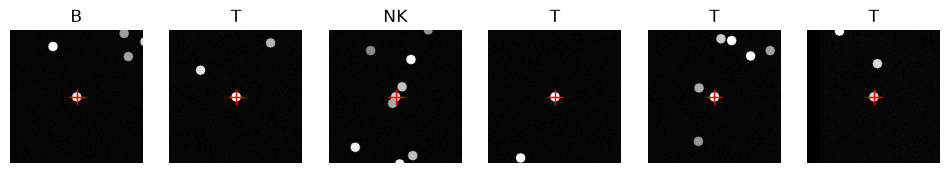

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 6, figsize=(12, 2.2))
c = tiles.shape[-1] // 2  # the center pixel of the crop
for ax, tile, cell_type in zip(axes, tiles.cpu(), batch["obs"]["cell_type"], strict=False):
    ax.imshow(tile[0], cmap="gray")
    ax.plot(c, c, "r+", markersize=12)  # the center of the crop: the cell this row belongs to
    ax.set_title(cell_type)
    ax.axis("off")

## Iterate

Each batch is a dictionary.
`X` is sparse: convert it to dense on the GPU (`.to(device).to_dense()`), which is much faster than doing it on the CPU.

In [8]:
for batch in loader:
    x = batch["X"].to(device).to_dense()
    tiles = batch["images"]["morphology_focus"]
    cell_type = batch["obs"]["cell_type"]
    # ... your training step here ...
    break

print(f"batch X: {tuple(x.shape)} {x.dtype} on {x.device}")
print(f"tiles:   {tuple(tiles.shape)}")
print(f"labels:  {cell_type[:5].tolist()}")

batch X: (32, 100) torch.float32 on cpu
tiles:   (32, 1, 224, 224)
labels:  ['NK', 'NK', 'NK', 'T', 'NK']


```{note}
Iterate the `Loader` directly. It already reads, shuffles and batches cells, so wrapping it in a {class}`torch.utils.data.DataLoader` would re-batch them and add worker processes on top of its own concurrent reads.
```

## Next steps

- {doc}`scrnaseq`: stream the expression of real Xenium slides, and use `load_table` to choose what is written.
- {doc}`images`: augment image and labels tiles together, and use the 1024-pixel context at several scales.
- {doc}`multimodal`: train a model on tiles and expression from the same batch.